# Banknote Authentication — TabICLv2 vs Random Forest (CPU)

So sánh một **tabular foundation model đã pretrain (TabICLv2)** với **mô hình truyền thống học từ đầu (Random Forest)** trên cùng dữ liệu.

- **Dataset:** UCI Banknote Authentication, **1.372 mẫu, 4 đặc trưng số**, 2 lớp `0`/`1`.
- **Đặc trưng:** `variance`, `skewness`, `curtosis`, `entropy`, trích xuất từ ảnh tiền giấy. Giữ nguyên cách viết `curtosis` của UCI.
- **Nguồn:** https://archive.ics.uci.edu/dataset/267/banknote+authentication
- **Trích dẫn:** Lohweg, V. (2012). Banknote Authentication [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55P57 — **CC BY 4.0**.
- Tải dữ liệu thật từ UCI lần đầu và lưu CSV cục bộ; không tạo dữ liệu hoặc kết quả giả.
- Dữ liệu, split và kết quả được lưu riêng; **không ghi đè thực nghiệm Breast Cancer**.

## 1. Môi trường và cấu hình
Chọn kernel của môi trường đã cài `tabicl`, `torch`, `numpy`, `pandas`, `scikit-learn`. Nếu thiếu, bỏ dấu `#` của dòng cài đặt bên dưới, chạy rồi restart kernel. Checkpoint cố định: `tabicl-classifier-v2-20260212.ckpt`.

In [1]:
# Chỉ bỏ dấu # nếu kernel đang thiếu thư viện:
# %pip install 'tabicl>=2.0' numpy pandas scikit-learn torch

from pathlib import Path
import hashlib
import importlib.metadata
import io
import json
import os
import platform
import time
import urllib.request
import zipfile

N_CPU_THREADS = min(4, os.cpu_count() or 2)
os.environ['CUDA_VISIBLE_DEVICES'] = ''
os.environ['OMP_NUM_THREADS'] = str(N_CPU_THREADS)
os.environ['MKL_NUM_THREADS'] = str(N_CPU_THREADS)

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if not (ROOT / 'datasets').is_dir():
    if (ROOT.parent / 'datasets').is_dir():
        ROOT = ROOT.parent
    else:
        raise FileNotFoundError('Mở notebook từ thư mục project hoặc notebooks.')
DATASET_ID = 'banknote_authentication'
DATASET = ROOT / 'datasets' / f'{DATASET_ID}.csv'
SPLITS = ROOT / 'splits'
RESULTS = ROOT / 'results' / DATASET_ID
SPLITS.mkdir(exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
SEEDS = [42]                     # Mở rộng sau: [42, 43, 44, 45, 46]
TRAIN_SIZES = [50, 100]           # Mở rộng sau: [50, 100, 200, 300]
CHECKPOINT = 'tabicl-classifier-v2-20260212.ckpt'
FEATURES = ['variance', 'skewness', 'curtosis', 'entropy']
SOURCE_URL = 'https://archive.ics.uci.edu/static/public/267/banknote+authentication.zip'


def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return 'not_installed'


VERSIONS = {name: package_version(name) for name in
            ['numpy', 'pandas', 'scikit-learn', 'torch', 'tabicl', 'threadpoolctl']}
print('Python:', platform.python_version(), '| CPU:', platform.machine(), '| threads:', N_CPU_THREADS)
print('Packages:', VERSIONS)
print('Kết quả riêng:', RESULTS)

Python: 3.14.6 | CPU: arm64 | threads: 4
Packages: {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'torch': '2.14.1', 'tabicl': '2.2.0', 'threadpoolctl': '3.7.0'}
Kết quả riêng: /Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/results/banknote_authentication


## 2. Tải và kiểm tra dữ liệu thật từ UCI

Lần đầu cần Internet; các lần sau đọc CSV đã lưu. Không chuẩn hóa cho Random Forest; TabICLv2 dùng preprocessing nội bộ. Cột `row_id` và `target` không được đưa vào đầu vào mô hình. SHA-256 của CSV được lưu để phát hiện dữ liệu thay đổi.

In [2]:
def validate_frame(data):
    assert list(data.columns) == ['row_id', *FEATURES, 'target'], data.columns.tolist()
    assert data.shape == (1372, 6), data.shape
    assert data['row_id'].tolist() == list(range(1372))
    assert not data.isna().any().any(), 'Dữ liệu có giá trị thiếu'
    assert np.isfinite(data[FEATURES].to_numpy(dtype=float)).all(), 'Đặc trưng không hữu hạn'
    assert set(data['target'].unique()) == {0, 1}, 'Nhãn không hợp lệ'


if not DATASET.exists():
    import ssl
    import certifi  # Đã có trong dependencies của tabicl/huggingface-hub.

    print('Đang tải dữ liệu từ UCI:', SOURCE_URL)
    tls_context = ssl.create_default_context(cafile=certifi.where())
    with urllib.request.urlopen(SOURCE_URL, timeout=60, context=tls_context) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as bundle:
        raw = bundle.read('data_banknote_authentication.txt')
    downloaded = pd.read_csv(io.BytesIO(raw), header=None, names=[*FEATURES, 'target'])
    downloaded.insert(0, 'row_id', np.arange(len(downloaded)))
    validate_frame(downloaded)
    downloaded.to_csv(DATASET, index=False)

frame = pd.read_csv(DATASET)
validate_frame(frame)
DATASET_SHA256 = hashlib.sha256(DATASET.read_bytes()).hexdigest()
X = frame[FEATURES].to_numpy(dtype=np.float32)
y = frame['target'].to_numpy(dtype=np.int64)
assert np.isfinite(X).all()
print('Dataset:', DATASET_ID, '| mẫu:', len(y), '| đặc trưng:', X.shape[1])
print('Số mẫu theo lớp:', dict(zip(*np.unique(y, return_counts=True))))
display(frame.head())

Dataset: banknote_authentication | mẫu: 1372 | đặc trưng: 4
Số mẫu theo lớp: {np.int64(0): np.int64(762), np.int64(1): np.int64(610)}


,row_id,variance,skewness,curtosis,entropy,target
0,0,3.62160,8.6661,-2.8073,-0.44699,0
1,1,4.54590,8.1674,-2.4586,-1.46210,0
2,2,3.86600,-2.6383,1.9242,0.10645,0
3,3,3.45660,9.5228,-4.0112,-3.59440,0
4,4,0.32924,-4.4552,4.5718,-0.98880,0


## 3. Protocol dùng chung và chỉ số đánh giá

- Chia phân tầng: **test 20%**, validation 20% của phần còn lại, train pool khoảng 64% tổng dữ liệu.
- Với seed 42: train pool **877**, validation **220**, test **275** mẫu. Chọn 50 hoặc 100 mẫu từ train pool; **cả hai mô hình dùng đúng cùng các chỉ số mẫu**, không chỉ cùng kích thước.
- Cấu hình định trước, **không tune bằng test**; validation được giữ riêng, chưa dùng để tune. Không fit/tune trên validation/test.
- Lưu split, train subsets và SHA-256 dữ liệu trong JSON riêng của Banknote.
- Accuracy, macro-F1, ROC-AUC: càng cao càng tốt. Log loss: càng thấp càng tốt. Đo `fit` và `predict_proba` riêng.
- Kết quả chỉ là pilot một dataset; không dùng để khẳng định mô hình nào tốt hơn trên mọi dataset.

In [3]:
def validate_indices(values):
    assert all(type(i) is int and 0 <= i < len(y) for i in values), 'Chỉ số không hợp lệ'
    assert len(set(values)) == len(values), 'Chỉ số trùng lặp'
    assert set(y[values]) == {0, 1}, 'Tập con phải có cả hai lớp'


def indices_for_seed(seed):
    path = SPLITS / f'{DATASET_ID}_seed{seed}.json'
    if path.exists():
        split = json.loads(path.read_text(encoding='utf-8'))
    else:
        pool, test = train_test_split(np.arange(len(y)), test_size=0.2,
                                      stratify=y, random_state=seed)
        train, val = train_test_split(pool, test_size=0.2,
                                     stratify=y[pool], random_state=seed)
        split = {'dataset': DATASET_ID, 'dataset_sha256': DATASET_SHA256, 'seed': seed,
                 'train': sorted(map(int, train)), 'val': sorted(map(int, val)),
                 'test': sorted(map(int, test)), 'train_subsets': {}}
    assert split['seed'] == seed and split['dataset'] == DATASET_ID
    assert split['dataset_sha256'] == DATASET_SHA256, 'CSV đã thay đổi so với split'
    parts = [split[key] for key in ['train', 'val', 'test']]
    for part in parts:
        validate_indices(part)
    merged = [i for part in parts for i in part]
    assert len(merged) == len(set(merged)) == len(y), 'Split bị chồng lặp hoặc thiếu mẫu'
    assert set(merged) == set(range(len(y)))
    path.write_text(json.dumps(split, indent=2), encoding='utf-8')
    return split, path


def make_fold(seed, n):
    split, path = indices_for_seed(seed)
    pool = np.asarray(split['train'], dtype=int)
    if not isinstance(n, int) or not 2 <= n <= len(pool):
        raise ValueError(f'n_train={n} không nằm trong [2, {len(pool)}]')
    subsets = split['train_subsets']
    if str(n) not in subsets:
        if n == len(pool):
            chosen = pool
        else:
            chosen, _ = train_test_split(pool, train_size=n, stratify=y[pool],
                                         random_state=seed + 101)
        subsets[str(n)] = sorted(map(int, chosen))
    chosen = subsets[str(n)]
    validate_indices(chosen)
    assert len(chosen) == n and set(chosen).issubset(split['train'])
    path.write_text(json.dumps(split, indent=2), encoding='utf-8')
    return X[chosen], y[chosen], X[split['test']], y[split['test']], chosen, split


def indices_hash(values):
    return hashlib.sha256(json.dumps(list(map(int, values))).encode()).hexdigest()


def metrics(y_true, prob, classes):
    classes = np.asarray(classes)
    p = np.asarray(prob, dtype=float)
    assert classes.shape == (2,) and set(classes.tolist()) == {0, 1}, classes
    assert p.shape == (len(y_true), 2), p.shape
    assert np.isfinite(p).all() and (p >= 0).all() and (p <= 1).all(), 'Xác suất không hợp lệ'
    assert np.allclose(p.sum(axis=1), 1.0, atol=1e-5), 'Tổng xác suất không bằng 1'
    p = p[:, [int(np.flatnonzero(classes == label)[0]) for label in [0, 1]]]
    pred = np.argmax(p, axis=1)
    p = np.clip(p, 1e-8, 1.0)
    p = p / p.sum(axis=1, keepdims=True)
    return {'accuracy': accuracy_score(y_true, pred),
            'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0),
            'roc_auc': roc_auc_score(y_true, p[:, 1]),
            'log_loss': log_loss(y_true, p, labels=[0, 1])}


for seed in SEEDS:
    for n in TRAIN_SIZES:
        xtr, ytr, xte, yte, chosen, split = make_fold(seed, n)
        assert len(ytr) == n and xtr.shape[1] == 4
        print(f'seed={seed}, train={n}, val={len(split["val"])}, test={len(yte)}, '
              f'train_hash={indices_hash(chosen)[:12]}')

seed=42, train=50, val=220, test=275, train_hash=f99d2c1434d9
seed=42, train=100, val=220, test=275, train_hash=96e5e74ddd64


## 4. Chạy hai mô hình trên CPU

- **TabICLv2:** checkpoint v2 cố định, `n_estimators=1`, `batch_size=1`, tắt AMP và FlashAttention; đây là cấu hình pilot tiết kiệm CPU, không phải cấu hình mặc định trong paper.
- **Random Forest:** 300 cây, các siêu tham số khác theo mặc định scikit-learn, `random_state=seed`, cùng giới hạn 4 luồng. Số cây của RF và số thành viên ensemble của TabICL có ý nghĩa khác nhau.
- Dùng cùng train/test và cùng ngân sách mẫu có nhãn; không tune riêng mô hình nào. TabICLv2 có lợi thế pretraining, RF học từ đầu: không phải so sánh cùng chi phí huấn luyện tổng thể.
- Ghi CSV sau mỗi lượt. Nếu TabICLv2 không tải được checkpoint, ghi `failed` và vẫn chạy Random Forest; **không thay checkpoint/mô hình**.
- **Thời gian `fit` của TabICLv2 có thể bao gồm tải/nạp checkpoint ở lần đầu**. Không dùng thời gian cold-start để kết luận tốc độ thuần; khi cần đo lại, chạy lại cell sau khi checkpoint đã cache.
- Chạy lại cell sẽ thay kết quả Banknote của cấu hình hiện tại; các kết quả Breast Cancer được giữ nguyên.

In [4]:
TABICL_PARAMS = dict(device='cpu', n_estimators=1, batch_size=1,
                     use_amp=False, use_fa3=False, offload_mode='auto',
                     checkpoint_version=CHECKPOINT, n_jobs=N_CPU_THREADS)
RF_PARAMS = dict(n_estimators=300, n_jobs=N_CPU_THREADS)
MODEL_IDS = ['RandomForest', 'TabICLv2']
RESULT_FILE = RESULTS / 'tabiclv2_vs_randomforest.csv'
RUN_CONFIG = {
    'dataset': DATASET_ID, 'dataset_sha256': DATASET_SHA256,
    'source_url': SOURCE_URL, 'doi': '10.24432/C55P57', 'license': 'CC BY 4.0',
    'n_samples': len(y), 'features': FEATURES, 'seeds': SEEDS, 'train_sizes': TRAIN_SIZES,
    'test_fraction': 0.2, 'validation_fraction_of_remaining': 0.2,
    'tabicl_params': TABICL_PARAMS, 'randomforest_params': RF_PARAMS,
    'python': platform.python_version(), 'platform': platform.platform(),
    'cpu_threads': N_CPU_THREADS, 'package_versions': VERSIONS,
    'timing_note': 'fit includes checkpoint loading/downloading if required; predict is predict_proba only',
    'started_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
}
(RESULTS / 'config.json').write_text(json.dumps(RUN_CONFIG, indent=2), encoding='utf-8')


def build_model(model_id, seed):
    if model_id == 'RandomForest':
        return RandomForestClassifier(**RF_PARAMS, random_state=seed)
    if model_id == 'TabICLv2':
        import torch
        from tabicl import TabICLClassifier

        torch.set_num_threads(N_CPU_THREADS)
        return TabICLClassifier(**TABICL_PARAMS, random_state=seed)
    raise ValueError(f'Mô hình không được hỗ trợ: {model_id}')


rows = []
for seed in SEEDS:
    for n in TRAIN_SIZES:
        for model_id in MODEL_IDS:
            row = {'model': model_id, 'dataset': DATASET_ID, 'seed': seed,
                   'train_size': n, 'status': 'failed',
                   **{key: np.nan for key in ['accuracy', 'macro_f1', 'roc_auc', 'log_loss',
                                              'fit_seconds', 'predict_seconds']},
                   'package_version': VERSIONS['tabicl' if model_id == 'TabICLv2' else 'scikit-learn'],
                   'checkpoint': CHECKPOINT if model_id == 'TabICLv2' else '',
                   'cpu_threads': N_CPU_THREADS, 'dataset_sha256': DATASET_SHA256,
                   'train_indices_sha256': '', 'test_indices_sha256': '', 'error': ''}
            print(f'Đang chạy {model_id}: seed={seed}, train={n}', flush=True)
            try:
                xtr, ytr, xte, yte, chosen, split = make_fold(seed, n)
                row['train_indices_sha256'] = indices_hash(chosen)
                row['test_indices_sha256'] = indices_hash(split['test'])
                model = build_model(model_id, seed)
                with threadpool_limits(limits=N_CPU_THREADS):
                    started = time.perf_counter()
                    model.fit(xtr, ytr)
                    row['fit_seconds'] = time.perf_counter() - started
                    started = time.perf_counter()
                    prob = model.predict_proba(xte)
                    row['predict_seconds'] = time.perf_counter() - started
                row.update(metrics(yte, prob, model.classes_))
                row['status'] = 'ok'
                print(f'  accuracy={row["accuracy"]:.4f}, macro_f1={row["macro_f1"]:.4f}, '
                      f'fit={row["fit_seconds"]:.3f}s, predict={row["predict_seconds"]:.3f}s', flush=True)
                del model
            except Exception as exc:
                row['error'] = repr(exc)[:1600]
                print('  FAILED:', row['error'], flush=True)
            rows.append(row)
            pd.DataFrame(rows).to_csv(RESULT_FILE, index=False)

runs = pd.DataFrame(rows)
RUN_CONFIG['finished_utc'] = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
(RESULTS / 'config.json').write_text(json.dumps(RUN_CONFIG, indent=2), encoding='utf-8')
print('Đã lưu:', RESULT_FILE)
display(runs[['model', 'seed', 'train_size', 'status', 'accuracy', 'macro_f1',
              'roc_auc', 'log_loss', 'fit_seconds', 'predict_seconds', 'error']])

Đang chạy RandomForest: seed=42, train=50
  accuracy=0.9127, macro_f1=0.9107, fit=0.122s, predict=0.024s
Đang chạy TabICLv2: seed=42, train=50


/Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  accuracy=0.9964, macro_f1=0.9963, fit=0.186s, predict=0.059s
Đang chạy RandomForest: seed=42, train=100
  accuracy=0.9455, macro_f1=0.9444, fit=0.106s, predict=0.025s
Đang chạy TabICLv2: seed=42, train=100
  accuracy=1.0000, macro_f1=1.0000, fit=0.076s, predict=0.043s
Đã lưu: /Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/results/banknote_authentication/tabiclv2_vs_randomforest.csv


,model,seed,train_size,status,accuracy,macro_f1,roc_auc,log_loss,fit_seconds,predict_seconds,error
0,RandomForest,42,50,ok,0.912727,0.910743,0.979508,0.220973,0.122218,0.024057,
1,TabICLv2,42,50,ok,0.996364,0.996320,0.999893,0.014799,0.186288,0.058916,
2,RandomForest,42,100,ok,0.945455,0.944393,0.995687,0.135200,0.106442,0.025148,
3,TabICLv2,42,100,ok,1.000000,1.000000,1.000000,0.001384,0.076323,0.042731,


## 5. Bảng và biểu đồ so sánh

Chỉ tổng hợp những cặp seed/train size mà **cả hai mô hình chạy thành công** và có cùng hash chỉ số train/test. Hiển thị số lượt thành công/thất bại để không che giấu lỗi. Xuất bảng tổng hợp và biểu đồ PNG để đưa vào slide.

Với một seed, độ lệch chuẩn là NaN (không đủ lần lặp để ước lượng), không được diễn giải là 0. Khi mở rộng nhiều seed, báo cáo mean/std và số seed; nếu seed bị lỗi thì cả hai mô hình đều bị loại khỏi cặp so sánh tương ứng.

Trạng thái các lượt chạy:


,model,status,n_runs
0,RandomForest,ok,2
1,TabICLv2,ok,2


Kết quả trên đúng cùng train/test:


,model,seed,train_size,accuracy,macro_f1,roc_auc,log_loss,fit_seconds,predict_seconds
0,RandomForest,42,50,0.912727,0.910743,0.979508,0.220973,0.122218,0.024057
1,TabICLv2,42,50,0.996364,0.996320,0.999893,0.014799,0.186288,0.058916
2,RandomForest,42,100,0.945455,0.944393,0.995687,0.135200,0.106442,0.025148
3,TabICLv2,42,100,1.000000,1.000000,1.000000,0.001384,0.076323,0.042731


Tổng hợp mean/std/count (std cần ít nhất 2 seed):


,model,train_size,accuracy_mean,accuracy_std,accuracy_count,macro_f1_mean,macro_f1_std,macro_f1_count,roc_auc_mean,roc_auc_std,roc_auc_count,log_loss_mean,log_loss_std,log_loss_count,fit_seconds_mean,fit_seconds_std,fit_seconds_count,predict_seconds_mean,predict_seconds_std,predict_seconds_count
0,RandomForest,50,0.912727,NaN,1,0.910743,NaN,1,0.979508,NaN,1,0.220973,NaN,1,0.122218,NaN,1,0.024057,NaN,1
1,RandomForest,100,0.945455,NaN,1,0.944393,NaN,1,0.995687,NaN,1,0.135200,NaN,1,0.106442,NaN,1,0.025148,NaN,1
2,TabICLv2,50,0.996364,NaN,1,0.996320,NaN,1,0.999893,NaN,1,0.014799,NaN,1,0.186288,NaN,1,0.058916,NaN,1
3,TabICLv2,100,1.000000,NaN,1,1.000000,NaN,1,1.000000,NaN,1,0.001384,NaN,1,0.076323,NaN,1,0.042731,NaN,1


model            RandomForest  TabICLv2  TabICLv2_minus_RF_percentage_points
seed train_size                                                             
42   50                0.9127    0.9964                               8.3636
     100               0.9455    1.0000                               5.4545

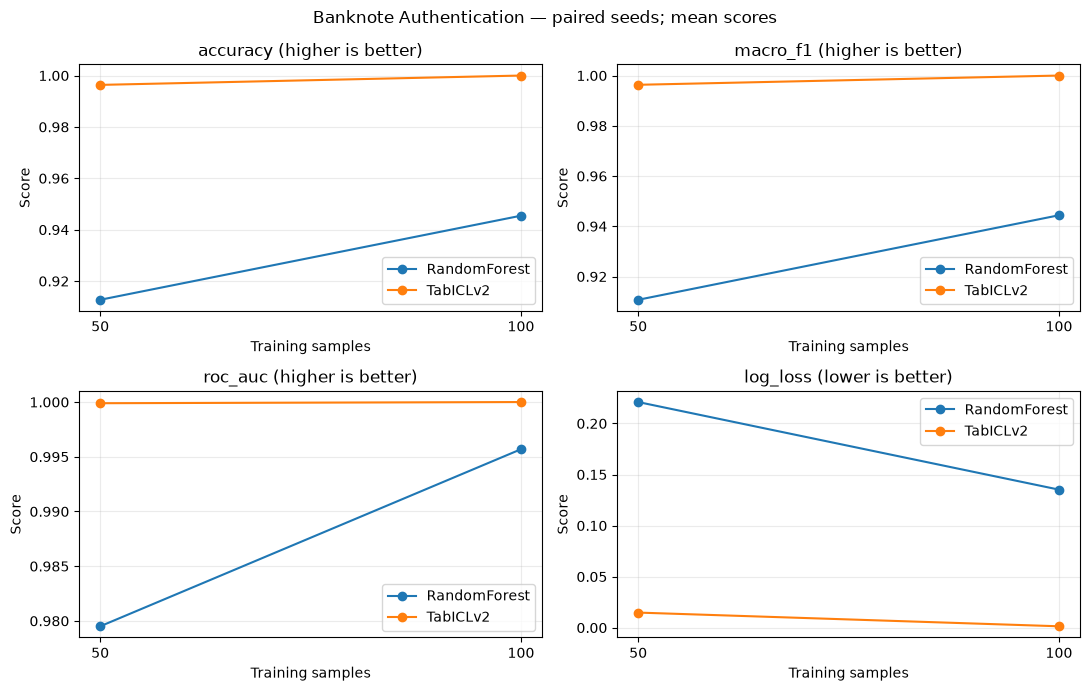

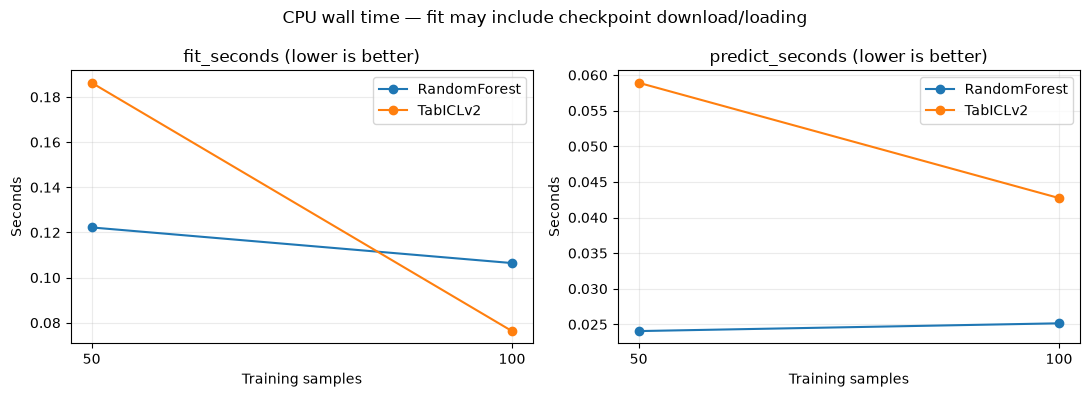

Bảng tổng hợp: /Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/results/banknote_authentication/summary.csv


In [5]:
runs = pd.read_csv(RESULT_FILE)
assert not runs.duplicated(['model', 'seed', 'train_size']).any()
assert runs['dataset'].eq(DATASET_ID).all()
assert runs['dataset_sha256'].eq(DATASET_SHA256).all()
print('Trạng thái các lượt chạy:')
display(runs.groupby(['model', 'status']).size().rename('n_runs').reset_index())

successful = runs.loc[runs['status'].eq('ok')].copy()
paired = successful.groupby(['seed', 'train_size']).filter(
    lambda group: set(group['model']) == set(MODEL_IDS)
)
for _, group in paired.groupby(['seed', 'train_size']):
    assert group['train_indices_sha256'].nunique() == 1, 'Hai mô hình dùng train khác nhau'
    assert group['test_indices_sha256'].nunique() == 1, 'Hai mô hình dùng test khác nhau'

SCORE_KEYS = ['accuracy', 'macro_f1', 'roc_auc', 'log_loss']
TIME_KEYS = ['fit_seconds', 'predict_seconds']
SUMMARY_FILE = RESULTS / 'summary.csv'
# Xóa biểu đồ cũ của lần chạy trước nếu lần này không có đủ cặp hợp lệ.
for artifact in ['metrics.png', 'timing.png']:
    (RESULTS / artifact).unlink(missing_ok=True)

summary = paired.groupby(['model', 'train_size'])[SCORE_KEYS + TIME_KEYS].agg(['mean', 'std', 'count'])
summary.columns = ['_'.join(column) for column in summary.columns]
summary = summary.reset_index()
summary.to_csv(SUMMARY_FILE, index=False)
if paired.empty:
    print('Chưa có cặp chạy thành công cho cả hai mô hình. Xem cột error, không suy diễn kết quả.')
    display(runs.loc[runs['status'].ne('ok'), ['model', 'seed', 'train_size', 'error']])
else:
    print('Kết quả trên đúng cùng train/test:')
    display(paired[['model', 'seed', 'train_size', *SCORE_KEYS, *TIME_KEYS]].round(6))
    print('Tổng hợp mean/std/count (std cần ít nhất 2 seed):')
    display(summary.round(6))
    accuracy_table = paired.pivot(index=['seed', 'train_size'], columns='model', values='accuracy')
    accuracy_table['TabICLv2_minus_RF_percentage_points'] = (
        accuracy_table['TabICLv2'] - accuracy_table['RandomForest']
    ) * 100
    display(accuracy_table.round(4))

    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print('Chưa có matplotlib: bảng CSV vẫn được lưu; cài matplotlib nếu muốn vẽ biểu đồ.')
    else:
        means = paired.groupby(['model', 'train_size'])[SCORE_KEYS + TIME_KEYS].mean()
        for filename, keys, shape in [('metrics.png', SCORE_KEYS, (2, 2)),
                                      ('timing.png', TIME_KEYS, (1, 2))]:
            fig, axes = plt.subplots(*shape, figsize=(11, 7 if len(keys) == 4 else 4))
            for ax, metric in zip(np.asarray(axes).ravel(), keys):
                for model_id in MODEL_IDS:
                    values = means.loc[model_id, metric].sort_index()
                    ax.plot(values.index, values.to_numpy(), marker='o', label=model_id)
                ax.set_title(metric + (' (higher is better)' if metric in SCORE_KEYS[:3]
                                      else ' (lower is better)'))
                ax.set_xlabel('Training samples')
                ax.set_ylabel('Seconds' if metric in TIME_KEYS else 'Score')
                ax.set_xticks(sorted(paired['train_size'].unique()))
                ax.grid(alpha=0.25)
                ax.legend()
            note = ('Banknote Authentication — paired seeds; mean scores' if filename == 'metrics.png'
                    else 'CPU wall time — fit may include checkpoint download/loading')
            fig.suptitle(note)
            fig.tight_layout()
            fig.savefig(RESULTS / filename, dpi=180, bbox_inches='tight')
            plt.show()
            plt.close(fig)
print('Bảng tổng hợp:', SUMMARY_FILE)